# Découverte du Dataset `wiring harness connectors segmen.v1i.yolov8`

Ce notebook est organisé en **blocs séparés** afin d'obtenir des **sorties (`outputs`) distinctes** pour chaque étape d'exploration :
1. Extraction de l'archive `.zip` (si nécessaire) et lecture de `data.yaml`.
2. Comptage des images et fichiers `.txt` par split (`train`, `valid`, `test`).
3. Analyse des classes et du nombre d'instances par classe.
4. Détection des fichiers labels vides (`0` octet) et vérification du format (polygones de segmentation `>= 6` coords vs boîtes `4` coords).
5. Inspection des résolutions d'images.
6. Visualisation d'exemples annotés (polygones de segmentation et boîtes).

## Bloc 1 — Chemins, extraction du ZIP et lecture de `data.yaml`

In [1]:
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

# Adaptez ces chemins selon votre emplacement réel
ZIP_PATH = Path("../data/raw/wiring harness connectors segmen.v1i.yolov8.zip").resolve()
DATASET_DIR = Path("../data/processed/wiring harness connectors segmen.v1i.yolov8").resolve()

if not DATASET_DIR.exists() and ZIP_PATH.exists():
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(DATASET_DIR)
    print(f"Archive extraite dans : {DATASET_DIR}")
elif DATASET_DIR.exists():
    print(f"Dossier dataset trouvé : {DATASET_DIR}")
else:
    print("Ni le ZIP ni le dossier extrait n'ont été trouvés. Vérifiez ZIP_PATH / DATASET_DIR.")

DATA_YAML = DATASET_DIR / "data.yaml"
with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

print("\nContenu de data.yaml :")
print(yaml.safe_dump(data_cfg, sort_keys=False, allow_unicode=True))

Dossier dataset trouvé : D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8

Contenu de data.yaml :
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 5
names:
- cable
- cable-tie
- clip
- connector
- label
roboflow:
  workspace: rafael-freitas
  project: wiring-harness-connectors-segmen
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/rafael-freitas/wiring-harness-connectors-segmen/dataset/1



## Bloc 2 — Comptage des images et labels par split (`train`, `valid`, `test`)

In [2]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
split_summary = []

for split in ["train", "valid", "test"]:
    img_dir = DATASET_DIR / split / "images"
    lbl_dir = DATASET_DIR / split / "labels"
    imgs = [p for p in img_dir.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS] if img_dir.exists() else []
    txts = list(lbl_dir.glob("*.txt")) if lbl_dir.exists() else []
    img_stems = {p.stem for p in imgs}
    txt_stems = {p.stem for p in txts}

    split_summary.append({
        "split": split,
        "images": len(imgs),
        "labels_txt": len(txts),
        "imgs_sans_txt": len(img_stems - txt_stems),
        "txt_sans_img": len(txt_stems - img_stems),
    })

df_splits = pd.DataFrame(split_summary)
display(df_splits)

,split,images,labels_txt,imgs_sans_txt,txt_sans_img
0,train,234,234,0,0
1,valid,22,22,0,0
2,test,11,11,0,0


## Bloc 3 — Distribution des classes et nombre d'instances

In [3]:
raw_names = data_cfg.get("names", {})
if isinstance(raw_names, dict):
    class_names = {int(k): v for k, v in raw_names.items()}
else:
    class_names = {i: v for i, v in enumerate(raw_names)}

class_rows = []
for split in ["train", "valid", "test"]:
    lbl_dir = DATASET_DIR / split / "labels"
    if not lbl_dir.exists():
        continue
    counts = Counter()
    for txt_file in lbl_dir.glob("*.txt"):
        for line in txt_file.read_text(encoding="utf-8").splitlines():
            parts = line.strip().split()
            if parts:
                counts[int(float(parts[0]))] += 1
    for cid, cname in sorted(class_names.items()):
        class_rows.append({
            "split": split,
            "class_id": cid,
            "class_name": cname,
            "instances": counts[cid]
        })

df_classes = pd.DataFrame(class_rows)
if not df_classes.empty:
    display(df_classes.pivot(index=["class_id", "class_name"], columns="split", values="instances").fillna(0).astype(int))

,split,test,train,valid
class_id,class_name,,,
0,cable,4,126,31
1,cable-tie,2,24,2
2,clip,0,62,5
3,connector,18,726,64
4,label,1,57,4


## Bloc 4 — Fichiers labels vides (`0` octet) et type d'annotations (polygones vs boîtes)

In [4]:
ann_audit = []
empty_files_by_split = {}

for split in ["train", "valid", "test"]:
    lbl_dir = DATASET_DIR / split / "labels"
    if not lbl_dir.exists():
        continue
    empty_files = []
    poly_count = 0
    box_count = 0
    other_count = 0

    for txt_file in sorted(lbl_dir.glob("*.txt")):
        lines = [ln.strip() for ln in txt_file.read_text(encoding="utf-8").splitlines() if ln.strip()]
        if not lines:
            empty_files.append(txt_file.name)
            continue
        for ln in lines:
            n_coords = len(ln.split()) - 1
            if n_coords >= 6 and n_coords % 2 == 0:
                poly_count += 1
            elif n_coords == 4:
                box_count += 1
            else:
                other_count += 1

    empty_files_by_split[split] = empty_files
    ann_audit.append({
        "split": split,
        "fichiers_vides_bg": len(empty_files),
        "polygones_seg": poly_count,
        "boites_4_coords": box_count,
        "lignes_atypiques": other_count
    })

display(pd.DataFrame(ann_audit))
for split, efiles in empty_files_by_split.items():
    print(f"[{split}] Exemples de fichiers .txt vides ({len(efiles)}) :", efiles[:5])

,split,fichiers_vides_bg,polygones_seg,boites_4_coords,lignes_atypiques
0,train,12,995,0,0
1,valid,2,106,0,0
2,test,0,25,0,0


[train] Exemples de fichiers .txt vides (12) : ['116_3058_jpg.rf.14e8769470e4a7050f346a9621b25de3.txt', '116_3058_jpg.rf.285f39d3c75d330274f47528f7286588.txt', '116_3058_jpg.rf.2a8aadc3c84cd891e7392a470faf09c8.txt', '119_16_jpg.rf.0e1d5346fb8f1be816c30a322fc066d5.txt', '119_16_jpg.rf.10f7eab529618a55afa260dea117f0d5.txt']
[valid] Exemples de fichiers .txt vides (2) : ['img_318_jpg.rf.b09635068b04139dda09586b2fd8772a.txt', 'WIN_20230804_09_45_26_Pro_jpg.rf.0c8c72963db433decf3a77a588950d2f.txt']
[test] Exemples de fichiers .txt vides (0) : []


## Bloc 5 — Résolutions des images

In [5]:
res_records = []
for split in ["train", "valid", "test"]:
    img_dir = DATASET_DIR / split / "images"
    if not img_dir.exists():
        continue
    for p in img_dir.iterdir():
        if p.is_file() and p.suffix.lower() in IMG_EXTS:
            im = cv2.imread(str(p))
            if im is not None:
                h, w = im.shape[:2]
                res_records.append({"split": split, "width": w, "height": h})
            else:
                res_records.append({"split": split, "width": -1, "height": -1})

df_res = pd.DataFrame(res_records)
if not df_res.empty:
    display(df_res.groupby(["split", "width", "height"]).size().reset_index(name="nb_images"))

,split,width,height,nb_images
0,test,640,640,11
1,train,640,640,234
2,valid,640,640,22


## Bloc 6 — Visualisation de quelques images annotées (`train`)

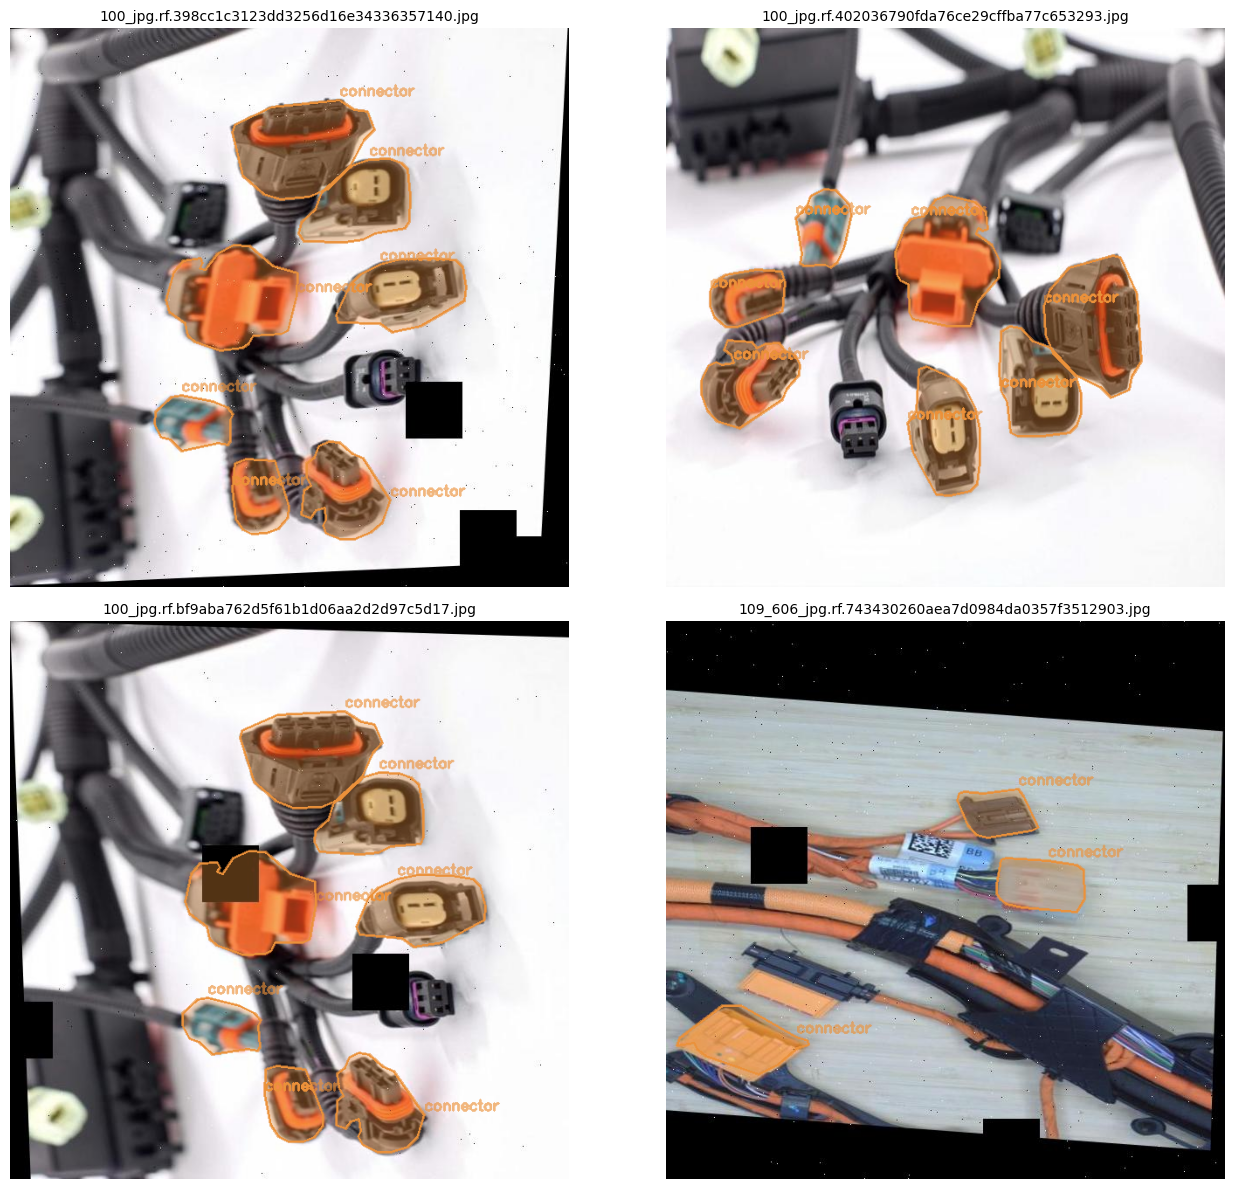

In [6]:
img_dir = DATASET_DIR / "train" / "images"
lbl_dir = DATASET_DIR / "train" / "labels"

sample_imgs = []
for p in sorted(img_dir.glob("*")):
    if p.suffix.lower() in IMG_EXTS:
        txt_p = lbl_dir / f"{p.stem}.txt"
        if txt_p.exists() and txt_p.read_text(encoding="utf-8").strip():
            sample_imgs.append((p, txt_p))
        if len(sample_imgs) == 4:
            break

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.reshape(-1)
rng = np.random.default_rng(42)
palette = {cid: tuple(int(c) for c in rng.integers(40, 240, size=3)) for cid in class_names}

for ax, (img_p, txt_p) in zip(axes, sample_imgs):
    img_bgr = cv2.imread(str(img_p))
    h, w = img_bgr.shape[:2]
    overlay = img_bgr.copy()

    for ln in txt_p.read_text(encoding="utf-8").splitlines():
        parts = ln.strip().split()
        if len(parts) < 5:
            continue
        cid = int(float(parts[0]))
        coords = [float(x) for x in parts[1:]]
        color = palette.get(cid, (0, 255, 0))
        label_txt = class_names.get(cid, str(cid))

        if len(coords) >= 6:
            pts = np.array(coords, dtype=np.float32).reshape(-1, 2)
            pts[:, 0] *= w
            pts[:, 1] *= h
            pts_i = pts.astype(np.int32)
            cv2.fillPoly(overlay, [pts_i], color)
            cv2.polylines(img_bgr, [pts_i], True, color, 2)
            x0, y0 = pts_i[0]
            cv2.putText(img_bgr, label_txt, (int(x0), max(18, int(y0) - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
        elif len(coords) == 4:
            xc, yc, bw, bh = coords
            x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
            x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
            cv2.rectangle(img_bgr, (x1, y1), (x2, y2), color, 2)
            cv2.putText(img_bgr, label_txt, (x1, max(18, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)

    blended = cv2.addWeighted(overlay, 0.35, img_bgr, 0.65, 0)
    ax.imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
    ax.set_title(img_p.name, fontsize=10)
    ax.axis("off")

for ax in axes[len(sample_imgs):]:
    ax.axis("off")

plt.tight_layout()
plt.show()